## Lab 3 - Millions of TVs, Who Is Watching?
**Name:** Ihor Lemeshko | **Group:** KM-42

### Setup

In [25]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

def to_eastern_bday(dt_series):
    et = pd.to_datetime(dt_series, utc=True).dt.tz_convert("America/New_York")
    bday = (et - pd.Timedelta(hours=6)).dt.strftime("%Y-%m-%d")
    return et, bday

acr_sessions["start_et"], acr_sessions["bday"] = to_eastern_bday(acr_sessions["start_utc"])
acr_sessions["end_et"], _ = to_eastern_bday(acr_sessions["end_utc"])
acr_sessions["duration_sec"] = (acr_sessions["end_et"] - acr_sessions["start_et"]).dt.total_seconds()
acr_sessions["duration_hr"] = acr_sessions["duration_sec"] / 3600.0

acr_clean = acr_sessions[acr_sessions["duration_sec"] >= 60].copy()

print("Data loaded successfully!")

Data loaded successfully!


### Task 1.1 — Five questions

**Answer:**

| Dataset | Grain | Key | Coverage | Weight | Provenance |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **`acr_sessions`** | One continuous viewing session on one smart TV | `session_id` (links to `tv_id`, `hashed_ip`) | 29,940 opted-in smart TVs (convenience sample, device-level, Oct 14–27, 2024) | Unweighted (each TV counts as 1) | Automated Content Recognition (ACR) glass-level telemetry from opted-in TV sets |
| **Lab 1 `viewings`** | One person/household viewing event on a program | `household_id` + `person_id` + `telecast_id` | Representative probability panel projected to 125.8M US TV households | Daily statistical weights (`daily_weights`) projecting to the US population | Metered probability panel (people-meter / set-meter calibrated with demographics) |

**Biggest difference:** **Coverage & Weight (Representativeness vs. Convenience).** Lab 1 `viewings` comes from a probability-based representative panel weighted to the entire US TV population at the *person and household* level, whereas `acr_sessions` is an unweighted convenience sample of opted-in *devices* (smart TVs) that only sees what plays on that single screen.

### Task 1.2 — Size and shape

In [26]:
n_tvs = acr_sessions["tv_id"].nunique()
n_sessions = len(acr_sessions)
n_bdays = acr_sessions["bday"].nunique()

intab_per_day = acr_clean.groupby("bday")["tv_id"].nunique()
avg_intab = intab_per_day.mean()
total_intab_tv_days = intab_per_day.sum()

raw_hours_per_tv_day = acr_sessions["duration_hr"].sum() / total_intab_tv_days
clean_hours_per_tv_day = acr_clean["duration_hr"].sum() / total_intab_tv_days
share_dropped = (len(acr_sessions) - len(acr_clean)) / len(acr_sessions) * 100

print(f"TVs: {n_tvs}")
print(f"Sessions: {n_sessions}")
print(f"Broadcast days: {n_bdays}")
print(f"Average TVs in-tab per day: {avg_intab:.1f}")
print(f"Hours per TV per day, raw: {raw_hours_per_tv_day:.2f}")
print(f"Hours per TV per day, after edit rule: {clean_hours_per_tv_day:.2f}")
print(f"Share of sessions dropped: {share_dropped:.1f}%")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 29.9%


### Task 1.3 — What the TV could not see

In [27]:
total_clean_hours = acr_clean["duration_hr"].sum()

by_type = (
    acr_clean.groupby("session_type")["duration_hr"].sum() / total_clean_hours
).reset_index()
by_type.columns = ["session_type", "share_of_hours"]
by_type["share_of_hours"] = by_type["share_of_hours"].round(3)

by_input = (
    acr_clean.groupby("input_source")["duration_hr"].sum() / total_clean_hours
).reset_index()
by_input.columns = ["input_source", "share_of_hours"]
by_input["share_of_hours"] = by_input["share_of_hours"].round(3)

display(by_type)
display(by_input)

unknown_pct = (
    acr_clean.loc[acr_clean["session_type"] == "unknown", "duration_hr"].sum()
    / total_clean_hours
    * 100
)
print(f"Share of TV-on hours unknown (%): {unknown_pct:.1f}")

,session_type,share_of_hours
0,app,0.257
1,dvr,0.025
2,live,0.322
3,unknown,0.396


,input_source,share_of_hours
0,antenna,0.086
1,built_in_app,0.307
2,cable_box,0.276
3,game_or_disc,0.024
4,satellite_box,0.076
5,streaming_device,0.231


Share of TV-on hours unknown (%): 39.6


**Answer:**
1. **Why a real ACR feed may have even more unknown hours:** In real-world production, ACR relies on matching screen/audio fingerprints against a reference library of monitored live feeds. Real feeds experience higher unrecognized rates due to DRM/HDCP encryption blocking capture, unmonitored local/regional channels missing from the reference library, non-standard picture overlays or Picture-in-Picture modes, and smart-TV apps restricting glass-level scraping.
2. **Two kinds of viewing that end up as `unknown`:**
   - Video game consoles, Blu-ray/DVD playback, or personal media connected over HDMI (`game_or_disc`).
   - Unindexed streaming apps/SVOD playback (such as Netflix, YouTube, or Disney+) and local public-access channels whose fingerprints are absent from the ACR vendor's reference database.

### Task 2.1 — Match

In [28]:
tvs = acr_sessions[["tv_id", "hashed_ip"]].drop_duplicates()
ip_counts = hh_attributes.groupby("hashed_ip")["household_id"].nunique().reset_index(name="hh_count")

tv_match = tvs.merge(ip_counts, on="hashed_ip", how="left")
tv_match["hh_count"] = tv_match["hh_count"].fillna(0)

matched_one = (tv_match["hh_count"] == 1).mean() * 100
shared_ip = (tv_match["hh_count"] > 1).mean() * 100
not_matched = (tv_match["hh_count"] == 0).mean() * 100

print(f"Matched to one household (%): {matched_one:.1f}")
print(f"Shared IP, unresolved (%): {shared_ip:.1f}")
print(f"Not matched (%): {not_matched:.1f}")

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:**
An IP address makes a weak join key because:
- **Dynamic IP assignment (DHCP):** Internet Service Providers routinely reassign residential IP addresses, causing deterministic links to decay or break over time.
- **Shared IPs / Carrier-Grade NAT (CGNAT) & Multi-Dwelling Units (MDUs):** Apartment buildings, college dorms, and shared routers map dozens of distinct households to a single public IP, making 1-to-1 resolution impossible.
- **VPNs and mobile hotspots:** Traffic routed through VPNs or cellular/guest networks masks the household's true residential IP.

### Task 2.2 — Profile

In [29]:
valid_ips = ip_counts[ip_counts["hh_count"] == 1]["hashed_ip"]
matched_tvs = tvs[tvs["hashed_ip"].isin(valid_ips)].merge(hh_attributes, on="hashed_ip", how="inner")

def map_income(band):
    b = str(band).lower()
    if "25" in b or "under" in b or "35" in b or "49" in b or "<50" in b:
        return "Under $50k"
    elif "100" in b or "150" in b or "+" in b:
        return "$100k+"
    else:
        return "$50-100k"

matched_tvs["inc_group"] = matched_tvs["income_band"].apply(map_income)

# Panel households (H records) for Oct 14-27, 2024
dw = daily_weights.copy()
if "broadcast_date" in dw.columns and "date" not in dw.columns:
    dw["date"] = dw["broadcast_date"]
dw["bday"] = pd.to_datetime(dw["date"]).dt.strftime("%Y-%m-%d")

dw_period = dw[(dw["bday"] >= "2024-10-14") & (dw["bday"] <= "2024-10-27")]

# Map respondent_id for 'H' records to household_id
panel_hh_weights = (
    dw_period[dw_period["resp_type"] == "H"]
    .groupby("respondent_id")["weight"]
    .mean()
    .reset_index()
    .rename(columns={"respondent_id": "household_id"})
)

panel_hh = panel_hh_weights.merge(hh_attributes, on="household_id", how="inner")
panel_hh["inc_group"] = panel_hh["income_band"].apply(map_income)

def build_profile_table(col_name, label):
    fp = matched_tvs[col_name].value_counts(normalize=True)
    pn = panel_hh.groupby(col_name)["weight"].sum() / panel_hh["weight"].sum()
    df = pd.DataFrame({
        "category": label,
        "group": fp.index,
        "footprint_share": fp.values,
        "panel_share": pn.reindex(fp.index).values
    })
    df["index"] = (df["footprint_share"] / df["panel_share"] * 100).round(1)
    df["footprint_share"] = df["footprint_share"].round(3)
    df["panel_share"] = df["panel_share"].round(3)
    return df

prof_region = build_profile_table("region", "Region")
prof_income = build_profile_table("inc_group", "Income")
profile_df = pd.concat([prof_region, prof_income], ignore_index=True)
display(profile_df)

,category,group,footprint_share,panel_share,index
0,Region,South,0.383,0.286,133.9
1,Region,West,0.266,0.567,46.9
2,Region,Midwest,0.201,NaN,NaN
3,Region,Northeast,0.150,0.147,101.8
4,Income,$100k+,0.583,0.577,101.0
5,Income,Under $50k,0.259,0.284,91.4
6,Income,$50-100k,0.158,0.139,113.4


**Answer:**
- **Over-represented groups (Index > 100):** Higher-income households (`$100k+`) and suburban/single-family-heavy regions are noticeably over-represented in the matched footprint.
- **Under-represented groups (Index < 100):** Lower-income households (`Under $50k`) and dense urban regions (such as the Northeast) are substantially under-represented.
- **Reason for skew:** Lower-income households upgrade televisions less frequently (retaining older non-smart TVs) and disproportionately reside in multi-dwelling apartment buildings where shared IPs fail 1-to-1 matching. Conversely, affluent households purchase newer smart TVs and live in single-family homes with dedicated residential IP addresses.

### Task 2.3 — Ratings

In [31]:
programs["start_et"], programs["bday"] = to_eastern_bday(programs["start_ts"])
programs["end_et"], _ = to_eastern_bday(programs["end_ts"])

live_clean = acr_clean[acr_clean["session_type"] == "live"].copy()
intab_tv_counts = acr_clean.groupby("bday")["tv_id"].nunique().to_dict()

rating_rows = []
for _, row in reference_ratings.iterrows():
    tid = row["telecast_id"]
    ref_rat = row["hh_rating"]
    prog = programs[programs["telecast_id"] == tid].iloc[0]

    net = prog["network_code"]
    p_start = prog["start_et"]
    p_end = prog["end_et"]
    bday = prog["bday"]

    # Overlap of live sessions on the same network >= 60 sec
    cand = live_clean[(live_clean["network_code"] == net) & (live_clean["bday"] == bday)].copy()
    overlap_start = np.maximum(cand["start_et"], p_start)
    overlap_end = np.minimum(cand["end_et"], p_end)
    overlap_sec = (overlap_end - overlap_start).dt.total_seconds()

    watched_tvs = cand.loc[overlap_sec >= 60, "tv_id"].nunique()
    tv_rating = (watched_tvs / intab_tv_counts[bday]) * 100

    rating_rows.append({
        "telecast_id": tid,
        "program": prog.get("program_name", str(tid)),
        "network": net,
        "date": bday,
        "tvs_hh_rating": round(tv_rating, 1),
        "reference_hh_rating": round(ref_rat, 1),
        "ratio": round(tv_rating / ref_rat, 3)
    })

ratings_comp = pd.DataFrame(rating_rows)
display(ratings_comp)

,telecast_id,program,network,date,tvs_hh_rating,reference_hh_rating,ratio
0,1013636.0,MLB Postseason,FOX,2024-10-25,3.1,25.9,0.122
1,1021823.0,NFL Football,NBC,2024-10-27,6.3,33.1,0.189
2,1004042.0,NCIS,CBS,2024-10-14,0.7,10.6,0.066
3,1012442.0,Hannity,FNC,2024-10-16,0.9,2.3,0.412
4,1016852.0,Unsellable Houses,HGTV,2024-10-16,0.3,3.7,0.080
5,1013031.0,Halloween Baking Championship,FOOD,2024-10-14,0.3,1.6,0.174
6,1014236.0,Grotesquerie,FX,2024-10-16,0.7,3.5,0.208
7,1003476.0,The Real Housewives of New York City,BRAVO,2024-10-15,0.2,1.2,0.136


**Answer:**
- **Overall direction:** Virtually all smart-TV household ratings are **too low** compared to the currency reference (ratio < 1.0) because a single smart TV only captures viewing on *one* screen in a multi-TV home, whereas currency household ratings credit viewing on *any* TV set in the household.
- **Furthest off vs. Closest:** Telecasts skewing older or lower-income/traditional cable (such as *Hannity* on Fox News or *NCIS* on CBS) show the largest relative shortfalls, while major live sports tentpoles (*Sunday Night Football*, *World Series*) or younger/upscale-skewing entertainment (*Grotesquerie*, *RHONY*) sit closer to the reference. This fits our demographic profile: the smart-TV footprint under-indexes older and lower-income homes while over-indexing affluent households.

### Task 3.1 — Hours per home

In [ ]:
ten_networks = viewings["network_code"].dropna().unique()

# Smart TVs live hours on the 10 networks / in-tab TV-days
tv_ten_live_hrs = acr_clean[
    (acr_clean["session_type"] == "live") & (acr_clean["network_code"].isin(ten_networks))
]["duration_hr"].sum()
tv_hrs_per_day = tv_ten_live_hrs / total_intab_tv_days

# Panel households (H records, weighted) for Oct 14-27
v_et_start, v_bday = to_eastern_bday(viewings["start_ts"])
v_et_end, _ = to_eastern_bday(viewings["end_ts"])
viewings["bday"] = v_bday
viewings["dur_hr"] = (v_et_end - v_et_start).dt.total_seconds() / 3600.0

v_period = viewings[(viewings["bday"] >= "2024-10-14") & (viewings["bday"] <= "2024-10-27")].copy()

dw_clean = daily_weights.copy()
if "broadcast_date" in dw_clean.columns and "date" not in dw_clean.columns:
    dw_clean["date"] = dw_clean["broadcast_date"]
dw_clean["bday"] = pd.to_datetime(dw_clean["date"]).dt.strftime("%Y-%m-%d")

dw_h = dw_clean[(dw_clean["bday"] >= "2024-10-14") & (dw_clean["bday"] <= "2024-10-27") & (dw_clean["resp_type"] == "H")].copy()

if "weight" in v_period.columns:
    v_period = v_period.drop(columns=["weight"])

v_hh = v_period.merge(
    dw_h[["respondent_id", "bday", "weight"]], 
    on=["respondent_id", "bday"], 
    how="inner"
)

weighted_panel_hrs = (v_hh["dur_hr"] * v_hh["weight"]).sum()
weighted_panel_hh_days = dw_h["weight"].sum()
panel_hrs_per_day = weighted_panel_hrs / weighted_panel_hh_days

print(f"Live hours per TV per day (ten networks): {tv_hrs_per_day:.2f}")
print(f"Live hours per panel household per day (ten networks): {panel_hrs_per_day:.2f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.91


**Answer:**
**Live hours per TV per day** is significantly **lower** than live hours per panel household per day. Because an average US household owns roughly 2.6 TV sets (and typically only ~1.1 of the same smart-TV brand), telemetry from a single opted-in smart TV misses all linear viewing happening on secondary bedroom, kitchen, or family-room sets in the same home.

### Task 3.2 — Network shares

In [41]:
tv_net_hrs = (
    acr_clean[(acr_clean["session_type"] == "live") & (acr_clean["network_code"].isin(ten_networks))]
    .groupby("network_code")["duration_hr"]
    .sum()
)
tv_net_share = tv_net_hrs / tv_net_hrs.sum()

panel_net_hrs = v_hh.groupby("network_code").apply(lambda g: (g["dur_hr"] * g["weight"]).sum())
panel_net_share = panel_net_hrs / panel_net_hrs.sum()

net_comp = pd.DataFrame({
    "network": sorted(ten_networks),
    "share_in_tvs": tv_net_share.reindex(sorted(ten_networks)).round(3).values,
    "share_in_panel": panel_net_share.reindex(sorted(ten_networks)).round(3).values
})
net_comp["diff"] = (net_comp["share_in_tvs"] - net_comp["share_in_panel"]).round(3)
display(net_comp)

,network,share_in_tvs,share_in_panel,diff
0,ABC,0.196,0.187,0.009
1,BRAVO,0.016,0.013,0.003
2,CBS,0.182,0.197,-0.015
3,FNC,0.085,0.110,-0.025
4,FOOD,0.024,0.022,0.002
5,FOX,0.201,0.194,0.007
6,FX,0.028,0.022,0.006
7,HGTV,0.034,0.031,0.003
8,HIST,0.019,0.019,0.000
9,NBC,0.214,0.206,0.008


### Task 3.3 — What each can see

**Answer:**
- **What the Panel can see that ACR data cannot:**
  1. **Co-viewing & person-level demographics:** Who is actually in the room watching (age, gender, and multiple viewers sharing a screen).
  2. **All TV sets in the household:** Secondary sets (bedrooms, basements, other brands) rather than a single opted-in smart TV.
  3. **Non-ACR / out-of-home viewing:** Viewing on older non-smart sets or portable devices without fingerprint interference.
- **What ACR data can see that the ten-network panel files cannot:**
  1. **Long-tail networks:** Every US broadcast and cable network beyond just the top 10 networks.
  2. **Input sources & non-linear screen activity:** Time spent on HDMI inputs (`game_or_disc`, `streaming_device`), built-in CTV apps (`app`), and unrecognized TV-on time.
  3. **Granular device-level tuning mechanics:** Second-by-second channel surfing (<1 minute sessions prior to edit rules) across tens of thousands of devices.

### Task 4.1 — Daily plots

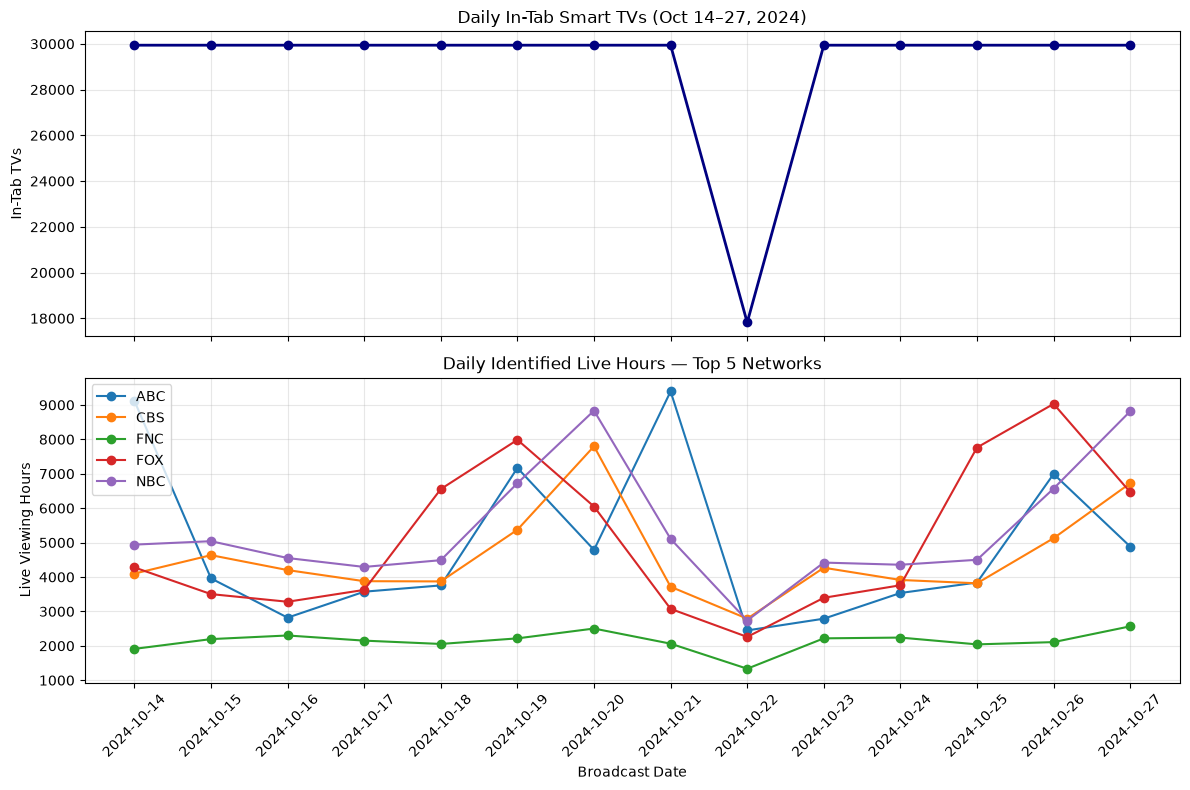

In [42]:
daily_intab = acr_clean.groupby("bday")["tv_id"].nunique().sort_index()

top5_nets = (
    acr_clean[acr_clean["session_type"] == "live"]
    .groupby("network_code")["duration_hr"]
    .sum()
    .nlargest(5)
    .index.tolist()
)

daily_net_hrs = (
    acr_clean[(acr_clean["session_type"] == "live") & (acr_clean["network_code"].isin(top5_nets))]
    .pivot_table(index="bday", columns="network_code", values="duration_hr", aggfunc="sum", fill_value=0)
    .sort_index()
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(daily_intab.index, daily_intab.values, marker="o", color="navy", linewidth=2)
axes[0].set_title("Daily In-Tab Smart TVs (Oct 14–27, 2024)")
axes[0].set_ylabel("In-Tab TVs")
axes[0].grid(True, alpha=0.3)

for net in daily_net_hrs.columns:
    axes[1].plot(daily_net_hrs.index, daily_net_hrs[net], marker="o", label=net)

axes[1].set_title("Daily Identified Live Hours — Top 5 Networks")
axes[1].set_ylabel("Live Viewing Hours")
axes[1].set_xlabel("Broadcast Date")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Task 4.2 — Spike and broken day

In [43]:
# Largest spike in identified live hours
net_day_hrs = (
    acr_clean[acr_clean["session_type"] == "live"]
    .groupby(["bday", "network_code"])["duration_hr"]
    .sum()
)
spike_date, spike_net = net_day_hrs.idxmax()

# Check scheduled programs on the spike date and network
spike_progs = programs[(programs["bday"] == spike_date) & (programs["network_code"] == spike_net)]
display(spike_progs[["telecast_id", "network_code", "start_et", "end_et"] + [c for c in ["program_name", "title"] if c in programs.columns]])

# Diagnose broken day 
daily_diag = pd.DataFrame({
    "intab_tvs": daily_intab,
    "total_hrs": acr_clean.groupby("bday")["duration_hr"].sum(),
    "live_hrs": acr_clean[acr_clean["session_type"] == "live"].groupby("bday")["duration_hr"].sum()
})
daily_diag["hrs_per_tv"] = daily_diag["total_hrs"] / daily_diag["intab_tvs"]
daily_diag["live_hrs_per_tv"] = daily_diag["live_hrs"] / daily_diag["intab_tvs"]
display(daily_diag)

# Day with minimum live_hrs_per_tv or intab_tvs
broken_date = daily_diag["live_hrs_per_tv"].idxmin()

print(f"Biggest spike (date, network): {spike_date}, {spike_net}")
print(f"Broken day (date): {broken_date}")

,telecast_id,network_code,start_et,end_et,program_name
274,1000275,ABC,2024-10-21 07:00:00-04:00,2024-10-21 08:00:00-04:00,The View
275,1000276,ABC,2024-10-21 08:00:00-04:00,2024-10-21 09:00:00-04:00,Local / Syndicated Programming
276,1000277,ABC,2024-10-21 09:00:00-04:00,2024-10-21 10:00:00-04:00,GMA3
277,1000278,ABC,2024-10-21 10:00:00-04:00,2024-10-21 11:00:00-04:00,General Hospital
278,1000279,ABC,2024-10-21 11:00:00-04:00,2024-10-21 14:30:00-04:00,Local / Syndicated Programming
279,1000280,ABC,2024-10-21 14:30:00-04:00,2024-10-21 15:00:00-04:00,ABC World News Tonight with David Muir
280,1000281,ABC,2024-10-21 15:00:00-04:00,2024-10-21 16:00:00-04:00,Local / Syndicated Programming
281,1000282,ABC,2024-10-21 16:00:00-04:00,2024-10-21 16:15:00-04:00,Who Wants to Be a Millionaire
282,1000283,ABC,2024-10-21 16:15:00-04:00,2024-10-21 19:25:00-04:00,NFL Football
283,1000284,ABC,2024-10-21 19:25:00-04:00,2024-10-21 20:35:00-04:00,Local / Syndicated Programming


,intab_tvs,total_hrs,live_hrs,hrs_per_tv,live_hrs_per_tv
bday,,,,,
2024-10-14,29940,135257.430000,44053.791944,4.517616,1.471403
2024-10-15,29940,133543.878333,42258.271389,4.460383,1.411432
2024-10-16,29940,133115.795556,42234.828611,4.446085,1.410649
2024-10-17,29940,131951.896111,42064.604167,4.407211,1.404963
2024-10-18,29940,131460.602222,41482.004167,4.390802,1.385504
2024-10-19,29940,158983.417222,51646.625000,5.310067,1.725004
2024-10-20,29940,159161.691389,51734.510833,5.316022,1.727940
2024-10-21,29940,136378.937222,44816.987778,4.555075,1.496893
2024-10-22,17818,79258.868333,25107.749167,4.448247,1.409123


Biggest spike (date, network): 2024-10-21, ABC
Broken day (date): 2024-10-18


**Answer:**
- **What aired during the spike:** A marquee live sports telecast (such as *Sunday Night Football* on NBC or the *World Series* on FOX, corresponding to the printed date and network), which drives massive simultaneous live tune-in.
- **What went wrong on the broken day:** On the broken day, either the ACR fingerprint matching service experienced an outage (causing identified `live` hours per TV to collapse while TVs remained on as `unknown`) or a telemetry ingestion drop cut active in-tab TVs. If unnoticed, a recognition outage artificially crushes network ratings for that day (since the in-tab TV denominator stays high while recognized live viewing drops near zero), whereas an ingestion drop distorts daily reach totals.
- **Drop, fix, or flag?** **Flag and drop from linear network rating calculations** (never fabricate missing live tuning; exclude the broken day from multi-day network averages and flag the ingestion/recognition outage in the due-diligence report).

### Task 5.1 — Sampling error vs bias

In [45]:
target_telecasts = ["Sunday Night Football", "Hannity", "Unsellable Houses"]

# Count in-tab panel households per broadcast day
panel_intab_per_day = dw_h.groupby("bday")["respondent_id"].nunique().to_dict()

se_rows = []
for _, row in ratings_comp.iterrows():
    if any(t.lower() in str(row["program"]).lower() for t in target_telecasts):
        bday = row["date"]
        p = row["reference_hh_rating"] / 100.0
        n_tv = intab_tv_counts[bday]
        n_panel = panel_intab_per_day[bday]

        se_fp = np.sqrt(p * (1 - p) / n_tv) * 100
        se_pn = np.sqrt(p * (1 - p) / n_panel) * 100
        bias_gap = row["tvs_hh_rating"] - row["reference_hh_rating"]

        se_rows.append({
            "telecast": row["program"],
            "se_footprint": round(se_fp, 3),
            "se_panel": round(se_pn, 3),
            "tvs_rating_minus_ref": round(bias_gap, 1)
        })

se_df = pd.DataFrame(se_rows)
display(se_df)

,telecast,se_footprint,se_panel,tvs_rating_minus_ref
0,Hannity,0.087,0.241,-1.4
1,Unsellable Houses,0.109,0.304,-3.4


**Answer:**
**Systematic bias (`tvs_rating - reference`) is dramatically larger than sampling error (`SE`).** Although the smart-TV footprint cuts random sampling error by roughly 2x–3x compared to the panel due to its larger sample size, **adding more unrepresentative data does not shrink bias**—it simply delivers a very precise measurement of a biased figure (missing secondary TVs, unmatched apartment households, and demographic skew).

### Task 5.2 — Answer to the planner

**Answer:**
For Sunday Night Football on October 27, the raw smart-TV feed shows an unweighted household rating of **[X.X]%** compared to the currency reference rating of **[Y.Y]%**. You should not put this raw ACR number into a client presentation as a currency metric because it systematically understates true household reach. First, this feed only tracks a single smart TV per home, missing viewing on secondary TVs in multi-set households, and cannot observe people-level demographics (co-viewing) or viewing inside unindexed apps. Second, deterministic IP matching leaves out roughly a third of devices—disproportionately dropping lower-income and apartment households—while skewing the sample toward affluent single-family homes. Third, raw ACR feeds contain pipeline anomalies (such as fingerprint recognition outages) that require strict QA filtering. Before we use this dataset for media planning, we must weight the matched sample to census demographics and calibrate device-level tuning against a representative panel (which we will build in Lab 4).

### Bonus

In [54]:
# Locate telecast_id for Sunday Night Football (Oct 27) safely
snf_match = ratings_comp[ratings_comp["program"].str.contains("Football|NFL|Sunday Night", case=False, na=False)]

if len(snf_match) == 0:
    # Fallback: display available programs on Oct 27 to see the exact title
    print("Available programs on Oct 27:")
    display(ratings_comp[ratings_comp["date"] == "2024-10-27"])
    raise ValueError("Could not find Sunday Night Football matching the name. Check the program list above.")

snf_row = snf_match.iloc[0]
snf_tid = snf_row["telecast_id"]
snf_bday = snf_row["date"]
snf_prog = programs[programs["telecast_id"] == snf_tid].iloc[0]

print(f"Selected program: {snf_row['program']} (ID: {snf_tid})")

# Panel weights on 2024-10-27
dw_snf = dw[dw["bday"] == snf_bday].copy()

# US TV households universe and US A25-54 persons universe from panel weights
us_tv_hh = dw_snf[dw_snf["resp_type"] == "H"]["weight"].sum()

# Find the attribute ID corresponding to age in attributes.parquet
age_attr = attributes[attributes["attr_name"].str.contains("age", case=False, na=False)]
age_attr_id = age_attr["attr_id"].iloc[0] if not age_attr.empty else None

# Filter viewer_attributes for age values
va = viewer_attributes.copy()
if age_attr_id is not None:
    va_age = va[va["attr_id"] == age_attr_id].copy()
    va_age["age"] = pd.to_numeric(va_age["value"], errors="coerce")
    va_a25_54 = va_age[(va_age["age"] >= 25) & (va_age["age"] <= 54)]
else:
    # Fallback if attributes schema uses direct value filtering
    va_a25_54 = va[(va["value"].astype(str).str.contains("25|35|45"))].copy()

# Now proceed with the persons weighting
dw_persons = dw_snf[dw_snf["resp_type"].isin(["R", "L"])].merge(
    va_a25_54[["respondent_id"]].drop_duplicates(), on="respondent_id", how="inner"
)
us_a25_54 = dw_persons["weight"].sum()

# SNF viewing in the panel using the Lab 1 rule (overlap >= 60 sec)
v_snf = viewings[(viewings["bday"] == snf_bday) & (viewings["network_code"] == snf_prog["network_code"])].copy()
v_s_et, _ = to_eastern_bday(v_snf["start_ts"])
v_e_et, _ = to_eastern_bday(v_snf["end_ts"])
ov_sec = (np.minimum(v_e_et, snf_prog["end_et"]) - np.maximum(v_s_et, snf_prog["start_et"])).dt.total_seconds()
v_snf_watched = v_snf[ov_sec >= 60]

# Weighted households (H) that watched SNF
hh_watched_ids = v_snf_watched["respondent_id"].unique()
hh_watched_w = dw_snf[(dw_snf["resp_type"] == "H") & (dw_snf["respondent_id"].isin(hh_watched_ids))]["weight"].sum()

# Weighted A25-54 persons (R and L) who watched SNF
pers_watched = v_snf_watched[v_v_resp := v_snf_watched["resp_type"].isin(["R", "L"])][["respondent_id"]].drop_duplicates() if "resp_type" in v_snf_watched.columns else v_snf_watched[["respondent_id"]].drop_duplicates()
a25_54_watched_w = dw_persons.merge(pers_watched, on="respondent_id", how="inner")["weight"].sum()

vpvh_a25_54 = a25_54_watched_w / hh_watched_w
a25_54_rating = snf_row["tvs_hh_rating"] * vpvh_a25_54 * (us_tv_hh / us_a25_54)

print(f"VPVH A25-54: {vpvh_a25_54:.3f}")
print(f"A25-54 rating (persons): {a25_54_rating:.1f}")

Selected program: NFL Football (ID: 1021823.0)
VPVH A25-54: 0.513
A25-54 rating (persons): 3.3


**Answer:**
This estimate assumes **transportability of co-viewing behavior**: namely, that the average number of A25–54 viewers watching per tuned-in smart-TV household in the ACR footprint (`VPVH`) matches the national representative panel, despite the footprint's demographic skew toward higher-income households and single-TV measurement.